# 多区域、Delta 与生境

按 **Shift+Enter** 从上到下逐单元运行。变量保留在当前内核中；如果修改上游参数，请重新运行其后的单元。

本教程使用固定合成数据，演示软件流程，不提供临床效能结论。需要完整仓库和对应原生安装包；实际源码版本和原生扩展身份请查看本次执行收据。

## 1. 环境与独立输出目录

确认后端为 Rust。后续每步都可以检查中间对象；示例数据生成辅助函数只负责小型输入构造。

In [1]:
from pathlib import Path
import sys, tempfile
from IPython.display import display, Image
# 从 Notebook 所在目录或仓库根目录启动均可。
REPO = Path(TUTORIAL_REPO_ROOT).resolve() if 'TUTORIAL_REPO_ROOT' in globals() else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'examples/native/_shared.py').exists()), None)
if REPO is None:
    raise RuntimeError('请先下载完整仓库，并在仓库内启动 Jupyter。')
sys.path.insert(0, str(REPO/'examples/native'))
import ov_radiomics as rad
print(rad.backend_info())
# 每次完整运行使用新目录，避免覆盖已有结果。
output = Path(TUTORIAL_RUN_ROOT) if 'TUTORIAL_RUN_ROOT' in globals() else Path(tempfile.mkdtemp(prefix='radiomics-04_regions_delta_habitat-'))
if 'TUTORIAL_RUN_ROOT' in globals():
    output.mkdir(parents=True, exist_ok=False)
root = output
print('输出目录:', output)
import hashlib, importlib.metadata, json, platform
runtime = {'interpreter': sys.executable, 'python': platform.python_version(),
           'package_source': rad.__file__, 'backend': rad.backend_info(),
           'packages': {name: importlib.metadata.version(name) for name in
                        ('ov-radiomics', 'numpy', 'pandas', 'matplotlib', 'ipykernel')}}
from ov_radiomics._backend import try_native
extension = try_native()
if extension is None:
    raise RuntimeError('本教程需要真实 Rust 原生扩展。')
runtime['native_path'] = extension.__file__
runtime['native_sha256'] = hashlib.sha256(Path(extension.__file__).read_bytes()).hexdigest()
runtime['package_python_sha256'] = {p.relative_to(Path(rad.__file__).parent).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                                  for p in sorted(Path(rad.__file__).parent.rglob('*.py'))}
(output/'tutorial-runtime.json').write_text(json.dumps(runtime, ensure_ascii=False, indent=2), encoding='utf-8')
 
import numpy as np
import pandas as pd
import ov_radiomics as rad
from _shared import output_arguments, extraction_config, stack_example_tables, write_json, provenance


{'metrics_backend': 'rust', 'rust_core_version': '0.1.0'}
输出目录: D:\radiomics-tutorial-validation\six-notebooks-final\04_regions_delta_habitat\artifacts


## 2. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [2]:
(yy, xx) = np.indices((9, 9))
affine = [[1.0, 0.0, 0.0, 10.0], [0.0, 2.0, 0.0, -20.0], [0.0, 0.0, 1.0, 3.0], [0.0, 0.0, 0.0, 1.0]]

## 3. 显式提取参数

Original 特征，固定分箱参数和方向聚合方式。示例参数不代表所有 CT/MR/PET 的通用推荐。

In [3]:
config = extraction_config()['extraction']
sources = {name: [] for name in ('CT_tumor', 'CT_ring', 'MR_tumor', 'MR_ring')}
for (timepoint, change) in [('T0', 0.0), ('T1', 0.75)]:
    for modality in ('CT', 'MR'):
        image = rad.image.from_array(2.0 + xx + 3.0 * yy + change + (xx * yy * 0.01 if modality == 'MR' else 0.0), affine=affine, spatial_unit='mm')
        tumor = rad.mask.from_array(((xx >= 3) & (xx <= 5) & (yy >= 3) & (yy <= 5)).astype(np.uint32), geometry=image.geometry)
        organ = rad.mask.from_array(np.ones((9, 9), dtype=np.uint32), geometry=image.geometry)
        ring = rad.mask.peritumoral_ring(tumor, inner_mm=0.0, outer_mm=3.0, organ_mask=organ)
        assert not np.any(tumor.array.astype(bool) & ring.array.astype(bool))
        for (region, mask) in [('tumor', tumor), ('ring', ring)]:
            sample = rad.ImageSample(dict(sample_id=modality + '-' + region + '-' + timepoint, patient_id='P1', lesion_id='L1', modality=modality, region=region, timepoint=timepoint, center='A'), image, mask)
            sources[modality + '_' + region].append(sample.extract(config))
        if modality == 'CT' and timepoint == 'T0':
            given = np.where(tumor.array > 0, np.where(xx < 5, 1, 2), 0).astype(np.uint32)
            habitat_mask = rad.mask.from_array(given, geometry=image.geometry)
            np.save(output / 'provided-habitat-mask.npy', given)
            for label in (1, 2):
                roi = rad.mask.select_labels(habitat_mask, [label])
                rad.ImageSample(dict(sample_id='provided-habitat-' + str(label), patient_id='P1'), image, roi).extract(config).save(output / ('provided-habitat-' + str(label) + '.csv'))

## 4. 严格对齐区域和模态

按患者、病灶、时间点对齐；模态与区域是显式可变化的字段。输入影像已经对齐，本包没有执行配准。

In [4]:
tables = {name: stack_example_tables(items) for (name, items) in sources.items()}

## 5. 拼接多区域特征

保留来源前缀和配对证据，检查结果中的 ID、列名与参数。

In [5]:
merged = rad.research.concat(tables, key_fields=['patient_id', 'lesion_id', 'timepoint'], varying_fields=['modality', 'region'], already_registered=True)
merged.save(output / 'multimodal-multiregion.parquet')
write_json(output / 'concat-provenance.json', merged.provenance)
display(merged.features.head())

,ID,CT_tumor::original_firstorder_10Percentile,CT_tumor::original_firstorder_90Percentile,CT_tumor::original_firstorder_Energy,CT_tumor::original_firstorder_Entropy,CT_tumor::original_firstorder_InterquartileRange,CT_tumor::original_firstorder_Kurtosis,CT_tumor::original_firstorder_Maximum,CT_tumor::original_firstorder_Mean,CT_tumor::original_firstorder_MeanAbsoluteDeviation,...,MR_ring::original_shape_basic_BoundingBoxMinX_index,MR_ring::original_shape_basic_BoundingBoxMinY_index,MR_ring::original_shape_basic_BoundingBoxMinZ_index,MR_ring::original_shape_basic_BoundingBoxSizeX_voxels,MR_ring::original_shape_basic_BoundingBoxSizeY_voxels,MR_ring::original_shape_basic_BoundingBoxSizeZ_voxels,MR_ring::original_shape_basic_CentroidX_mm,MR_ring::original_shape_basic_CentroidY_mm,MR_ring::original_shape_basic_CentroidZ_mm,MR_ring::original_shape_basic_VoxelCount
0,CT-tumor-T0,14.80,21.20,2976.0000,3.169925,4.0,1.77,22.00,18.00,2.222222,...,0.0,2.0,0.0,9.0,5.0,1.0,14.0,-12.0,3.0,32.0
1,CT-tumor-T1,15.55,21.95,3224.0625,3.169925,4.0,1.77,22.75,18.75,2.222222,...,0.0,2.0,0.0,9.0,5.0,1.0,14.0,-12.0,3.0,32.0


## 6. 计算纵向变化

显式指定基线与随访。相对变化是比例；零分母示例使用缺失策略，不伪造零变化。

In [6]:
change = rad.research.delta(tables['CT_tumor'], baseline='T0', followup='T1', zero_denominator='missing')
change.save(output / 'delta.csv')
write_json(output / 'delta-pairing.json', change.provenance)
display(change.features.head())

,ID,original_firstorder_10Percentile::difference,original_firstorder_10Percentile::ratio,original_firstorder_10Percentile::relative_change,original_firstorder_90Percentile::difference,original_firstorder_90Percentile::ratio,original_firstorder_90Percentile::relative_change,original_firstorder_Energy::difference,original_firstorder_Energy::ratio,original_firstorder_Energy::relative_change,...,original_shape_basic_CentroidX_mm::relative_change,original_shape_basic_CentroidY_mm::difference,original_shape_basic_CentroidY_mm::ratio,original_shape_basic_CentroidY_mm::relative_change,original_shape_basic_CentroidZ_mm::difference,original_shape_basic_CentroidZ_mm::ratio,original_shape_basic_CentroidZ_mm::relative_change,original_shape_basic_VoxelCount::difference,original_shape_basic_VoxelCount::ratio,original_shape_basic_VoxelCount::relative_change
0,"[""delta"",[""P1"",""L1"",""CT"",""tumor""],""T0"",""T1""]",0.75,1.050676,0.050676,0.75,1.035377,0.035377,248.0625,1.083354,0.083354,...,0.0,0.0,1.0,-0.0,0.0,1.0,0.0,0.0,1.0,0.0


## 7. 已有矩阵上的局部生境

输入是已有强度/特征矩阵。聚类标签仅对本次拟合有意义，不能解释成跨患者一致的组织类别。

In [7]:
training = pd.DataFrame([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [8.0, 8.0], [9.0, 8.0], [8.0, 9.0], [9.0, 9.0]], columns=['intensity_a', 'intensity_b'], index=['voxel-' + str(i) for i in range(8)])
if hasattr(training, 'head'):
    display(training.head())

,intensity_a,intensity_b
voxel-0,0.0,0.0
voxel-1,1.0,0.0
voxel-2,0.0,1.0
voxel-3,1.0,1.0
voxel-4,8.0,8.0


## 8. 拟合与保存聚类

保存缩放参数和中心；预测时复用这些状态，并检查模型加载后结果一致。

In [8]:
habitat = rad.habitat.fit(training, clusters=2, initial_centers=[[0.0, 0.0], [8.0, 8.0]])
habitat.save(output / 'local-habitat.json')

## 9. 保存与重新加载

使用类型化 .rad 模型，检查加载后预测一致。重新运行保存单元前请改用新的输出目录。

In [9]:
restored = rad.habitat.HabitatModel.load(output / 'local-habitat.json')
pd.testing.assert_frame_equal(habitat.predict(training), restored.predict(training))
habitat.predict(training).to_csv(output / 'local-habitat-labels.csv', index=False)
habitat.centers_.to_csv(output / 'local-habitat-centers.csv', index=False)
provenance(output, '04_regions_delta_habitat', registration='caller-declared synthetic common grid; none performed', ring='Euclidean mm distance with x=1mm/y=2mm anisotropy and organ intersection', delta='explicit paired patient/lesion/modality/region; relative change is a fraction; zero denominator policy=missing', habitat='single local fit; cluster numbers do not imply shared histologic tissue types')

## 10. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [10]:
print('Outputs:', output)

Outputs: D:\radiomics-tutorial-validation\six-notebooks-final\04_regions_delta_habitat\artifacts


## 用实际结果绘图

仅展示本次合成数据计算结果；请核对患者层级、坐标与单位。

In [11]:
import matplotlib.pyplot as plt
labels = habitat.predict(training)['cluster'].to_numpy()
fig, ax = plt.subplots(figsize=(5, 4))
for cluster in sorted(set(labels)):
    points = training.loc[labels==cluster]
    ax.scatter(points['intensity_a'], points['intensity_b'], label='Local cluster '+str(cluster))
centers = habitat.centers_
ax.scatter(centers['intensity_a'], centers['intensity_b'], marker='x', s=100, c='black', label='Saved centers')
ax.set(xlabel='Synthetic intensity a', ylabel='Synthetic intensity b', title='One local habitat fit')
ax.legend()
fig.tight_layout()
fig.savefig(output/'local-habitat.png', dpi=140)
plt.close(fig)

## 查看导出的图与文件

查看图表的坐标、单位和预测层级。输出目录保留完整结果；这里显示前两幅图。

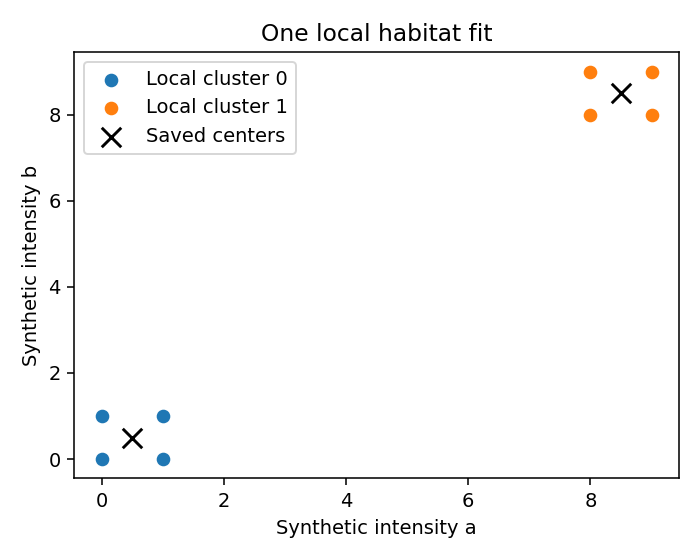

结果文件: ['concat-provenance.json', 'delta-pairing.json', 'delta.csv', 'delta.csv.manifest.json', 'local-habitat-centers.csv', 'local-habitat-labels.csv', 'local-habitat.json', 'local-habitat.png', 'multimodal-multiregion.parquet', 'multimodal-multiregion.parquet.manifest.json', 'provenance.json', 'provided-habitat-1.csv', 'provided-habitat-1.csv.manifest.json', 'provided-habitat-2.csv', 'provided-habitat-2.csv.manifest.json', 'provided-habitat-mask.npy', 'tutorial-runtime.json']


In [12]:
for figure in sorted(output.glob('*.png'))[:2]:
    display(Image(filename=str(figure)))
print('结果文件:', [p.name for p in sorted(output.iterdir())])

## 换成自己的数据

保持示例的 ID、患者/切片层级与列角色约定，先替换数据读取步骤，再重新运行下游单元。先确认几何、单位、缺失状态和队列重叠；不要用测试集决定阈值或筛选参数。

重新运行全部单元会新建结果目录；只重跑保存单元可能因为文件已存在而报错，这是显式防覆盖行为。